# Channel Shapley values

The players are the 32 output channels of `conv2`. The value of a coalition $S$ is the negative mean cross-entropy loss of the network on the 5 000 validation images when only the channels in $S$ are active:

$$v(S) = -\frac{1}{|D_\text{val}|} \sum_{(x, y) \in D_\text{val}} \mathcal{L}\big(f(x; m_S), y\big), \qquad m_S \in \{0, 1\}^{32}.$$

The notebook asks two questions: does the Shapley ranking identify the channels the trained network relies on, and does it give better pruned networks than a random or an L1-norm selection once these are fine-tuned?

In [1]:
import matplotlib.pyplot as plt

from shapley_pruning.data import load_cifar10
from shapley_pruning.experiments import (fine_tuned_accuracies, masked_accuracies, rank_correlation,
                                         summarize, top_k_coalition_values)
from shapley_pruning.plots import STYLES, plot_rules
from shapley_pruning.pruning import count_parameters, l1_channel_scores, prune_channels, to_mask, top_k
from shapley_pruning.shapley import channel_game, percent_correct, permutation_shapley
from shapley_pruning.training import accuracy, get_parent

## 1. Data and parent network

45 000 training, 5 000 validation and 10 000 test images. The parent network is trained for 10 epochs with Adam (learning rate $10^{-3}$) and saved to `checkpoints/parent.pt`, which the other notebooks load.

In [2]:
data = load_cifar10()
parent = get_parent(data)
full_accuracy = accuracy(parent, data.test)
print(f"{count_parameters(parent):,} parameters, test accuracy {full_accuracy:.2f}%")

273,706 parameters, test accuracy 71.24%


## 2. Monte Carlo estimate of the Shapley values

The Shapley value of channel $i$ is its marginal contribution averaged over all orderings $\sigma$ of the players, where $P_i^\sigma$ is the set of players before $i$:

$$\phi_i = \frac{1}{n!} \sum_{\sigma} \Big[v\big(P_i^\sigma \cup \{i\}\big) - v\big(P_i^\sigma\big)\Big].$$

The exact sum needs the value of all $2^{32}$ coalitions. Instead, $M$ orderings are drawn uniformly at random. Adding the channels one at a time along an ordering costs $n + 1 = 33$ evaluations and gives one marginal contribution per channel, so $\hat\phi_i$ is a mean of $M$ independent samples with standard error $s_i / \sqrt{M}$. Along each ordering the contributions telescope to $v(N) - v(\varnothing)$, so the estimate satisfies the efficiency axiom exactly. $v(\varnothing)$ is evaluated, not assumed to be zero: with every channel masked the network still outputs `fc2(relu(fc1.bias))`, the same prediction for every image.

In [3]:
game = channel_game(parent, data.val)
estimate = permutation_shapley(game, n_permutations=500)
phi, std_error = estimate.values, estimate.std_error

print(f"v(∅) = {estimate.empty_value:.4f}, v(N) = {estimate.full_value:.4f}")
print(f"Σ φ = {phi.sum():.4f},  v(N) − v(∅) = {estimate.full_value - estimate.empty_value:.4f}")
print(f"largest standard error: {std_error.max():.4f}")
half = len(estimate.marginals) // 2
first_half, second_half = estimate.marginals[:half].mean(0), estimate.marginals[half:].mean(0)
print(f"rank correlation between the estimates from each half of the orderings: "
      f"{rank_correlation(first_half, second_half):.3f}")

v(∅) = -2.3265, v(N) = -0.8922
Σ φ = 1.4343,  v(N) − v(∅) = 1.4343
largest standard error: 0.0074
rank correlation between the estimates from each half of the orderings: 0.963


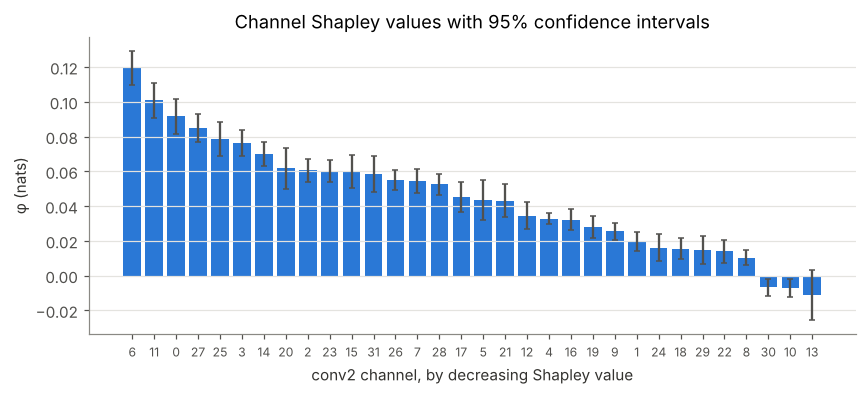

In [4]:
order = phi.argsort(descending=True)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(phi)), phi[order], yerr=1.96 * std_error[order],
       color=STYLES["Shapley"][0], ecolor="#52514e", capsize=2)
ax.set_xticks(range(len(phi)), order.tolist(), fontsize=8)
ax.set_xlabel("conv2 channel, by decreasing Shapley value")
ax.set_ylabel("φ (nats)")
ax.set_title("Channel Shapley values with 95% confidence intervals")
ax.grid(axis="x", visible=False)
fig.savefig("images/channel_shapley_values.png")
plt.show()

29 of the 32 channels have a positive value and three are slightly negative. The estimates from the two halves of the orderings rank the channels almost identically, so 500 orderings are enough to rank them, even though neighbouring values often differ by less than their confidence intervals.

## 3. Accuracy of the ranking without retraining

The parent network is evaluated on the test set with only the $k$ selected channels active. The rules are the $k$ highest Shapley values, the $k$ lowest, the $k$ filters with the largest L1 norm, and 20 random draws.

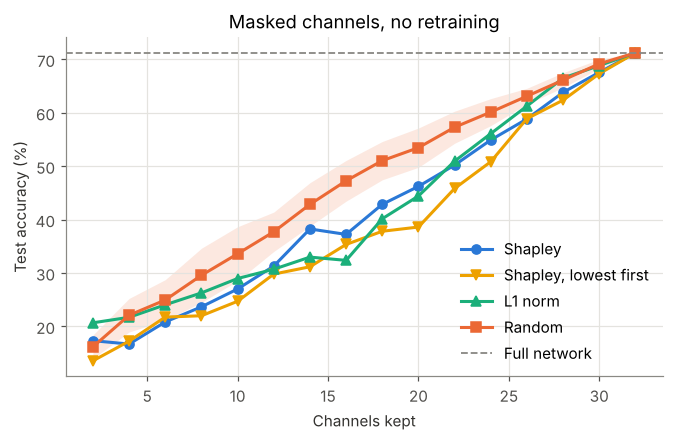

rule,Shapley,"Shapley, lowest first",L1 norm,Random
k,,,,
4,16.71,17.25,21.72,22.11 ± 3.14
8,23.68,22.01,26.29,29.58 ± 5.07
16,37.24,35.36,32.38,47.28 ± 3.81
24,54.92,50.85,56.11,60.14 ± 2.53


In [5]:
test_game = channel_game(parent, data.test, payoff=percent_correct)
rankings = {"Shapley": phi, "Shapley, lowest first": -phi, "L1 norm": l1_channel_scores(parent)}
masked = masked_accuracies(test_game, rankings, sizes=range(2, 33, 2))

fig, ax = plt.subplots(figsize=(7, 4))
plot_rules(ax, masked, reference=full_accuracy)
ax.set_xlabel("Channels kept")
ax.set_title("Masked channels, no retraining")
fig.savefig("images/channel_masked_accuracy.png")
plt.show()
summarize(masked[masked.k.isin([4, 8, 16, 24])])

Without retraining, the Shapley ranking does no better than keeping the lowest values, and both stay below the random draws from 4 to 30 channels: with 16 channels the top Shapley values give 37.2% against 47.3 ± 3.8% for random channels.

## 4. The value of the top coalition

A Shapley value averages a channel's marginal contributions over coalitions drawn at random. The top-$k$ coalition is a particular one, made only of high-value channels, and its value equals the additive prediction $v(\varnothing) + \sum_{i \in S} \phi_i$ only if the channels do not interact. The table compares the two on the validation images, with the mean value of 20 random coalitions of the same size.

In [6]:
top_k_coalition_values(game, estimate, sizes=[4, 8, 16, 24]).round(3)

,v(top k),v(∅) + Σ φ over the top k,"v(random k), mean"
k,,,
4,-2.461,-1.930,-2.300
8,-2.403,-1.643,-2.229
16,-2.032,-1.197,-1.639
24,-1.398,-0.938,-1.248


The top coalitions fall far short of their additive prediction, and below random coalitions of the same size. The four most valuable channels together do worse than no channel at all: $v = -2.461$ against $v(\varnothing) = -2.327$. Each of them helps on average when it joins a random coalition, but fc1 and its ReLU combine the channels non-linearly, so what a channel adds depends strongly on the channels already present. The Shapley value is an average contribution over random coalitions. It does not give the value of a particular coalition, and here the top-$k$ coalition is not even as good as a random one.

## 5. Pruning and fine-tuning

Each selection becomes a smaller network: `prune_channels` removes the conv2 filters outside the selection and the fc1 columns that read their feature maps. Its output equals the masked parent's:

In [7]:
keep = top_k(phi, 8)
pruned = prune_channels(parent, keep)
images = data.test.images[:500]
difference = (pruned(images) - parent(images, channel_mask=to_mask(keep, 32))).abs().max()
print(f"{count_parameters(pruned):,} parameters, largest output difference {difference:.1e}")

70,162 parameters, largest output difference 2.9e-06


Every pruned network is fine-tuned on the training set for 3 epochs with Adam (learning rate $10^{-4}$) and evaluated on the test set. Each rule is fine-tuned with the seeds 0, 1 and 2; the random rule draws a new set of channels for each seed.

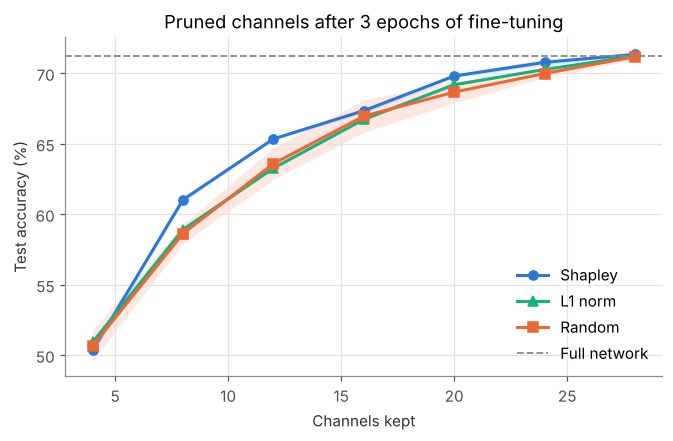

rule,Shapley,L1 norm,Random
k,,,
4,50.34 ± 0.30,50.91 ± 0.13,50.66 ± 1.06
8,61.03 ± 0.18,58.92 ± 0.19,58.62 ± 0.69
12,65.34 ± 0.06,63.27 ± 0.09,63.58 ± 1.12
16,67.35 ± 0.18,66.74 ± 0.13,66.96 ± 1.15
20,69.81 ± 0.13,69.19 ± 0.13,68.67 ± 0.76
24,70.78 ± 0.23,70.27 ± 0.03,69.99 ± 0.28
28,71.35 ± 0.09,71.22 ± 0.23,71.18 ± 0.22


In [8]:
fine_tuned = fine_tuned_accuracies(parent, data, "channels",
                                   {"Shapley": phi, "L1 norm": l1_channel_scores(parent)},
                                   sizes=[4, 8, 12, 16, 20, 24, 28])

fig, ax = plt.subplots(figsize=(7, 4))
plot_rules(ax, fine_tuned, reference=full_accuracy)
ax.set_xlabel("Channels kept")
ax.set_title("Pruned channels after 3 epochs of fine-tuning")
fig.savefig("images/channel_fine_tuned_accuracy.png")
plt.show()
summarize(fine_tuned)

After fine-tuning the order reverses. The Shapley selection is the best rule at 8, 12, 20 and 24 channels, 0.8 to 2.4 points above the random mean and outside its spread: with 8 channels, 61.03 ± 0.18% against 58.62 ± 0.69%. At 4, 16 and 28 channels the rules are within the spread of the random draws. The L1 norm does no better than random. Once fc1 is retrained on the channels that are kept, the channels with high Shapley values are the more useful ones in this network. The gap stays small, as 3 epochs of fine-tuning recover most of the accuracy whichever channels are kept.